# 03_8. Risk scale for people (post hoc) / Шкала риска для людей (post hoc)

**EN.** How the risk of a loan is shown to people. Y1 is rare (mean PD about 0.2 %), so the calibrated PD of even a risky loan is a small number. The PD stays the number for expected loss and provisions; next to it three readable scales are shown: the **relative risk** (PD / mean PD of the portfolio on the same date), the **percentile** (share of loans of the same date with a lower PD, 0 … 1) and the **risk class** 1–10 on fixed PD edges (the alert threshold PD ≥ 1 % opens class 7). Scorecard-style **points** are shown for reference. All scales are monotone in PD, so AUC, recall and the alert list do not change. **Post hoc, descriptive:** test was opened earlier under the frozen protocol; this notebook only reads the saved test predictions of `03_6`, no model is refitted or recalibrated, and the class edges are round PD values fixed before looking at test (`xai_ews.evaluation.risk_scale`).

**RU.** Как показывать риск кредита людям. Событие Y1 редкое (средняя PD около 0,2 %), поэтому откалиброванная PD даже рискованного кредита — маленькое число. PD остаётся числом для расчёта ожидаемого убытка и резервов; рядом показываются три понятные шкалы: **относительный риск** (PD / средняя PD портфеля на ту же дату), **процентиль** (доля кредитов той же даты с меньшей PD, от 0 до 1) и **класс риска** 1–10 на фиксированных границах PD (порог тревоги PD ≥ 1 % открывает класс 7). Для справки — **баллы** в стиле скоринговой карты. Все шкалы монотонны по PD, поэтому AUC, полнота и список тревог не меняются. **Post hoc, описательно:** test открыт раньше по замороженному протоколу; ноутбук только читает сохранённые прогнозы test из `03_6`, модели не переобучаются и не перекалибровываются, а границы классов — круглые значения PD, зафиксированные до просмотра test (`xai_ews.evaluation.risk_scale`).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.evaluation import risk_scale as rs
from xai_ews.evaluation.el import alert_threshold
from xai_ews.paths import MODELING_DIR, PREDICTIONS_DIR

OUT = MODELING_DIR / "test"
MODELS = {"m1_y1": "CatBoost M1", "b0_y1": "Scorecard B0"}
assert rs.GRADE_EDGES[rs.ALERT_GRADE - 2] == alert_threshold()

t = (pl.read_parquet(PREDICTIONS_DIR / "test_frame_y1.parquet", columns=["loan_identifier", "m", "y1", "excl_main", *[f"pd_{k}" for k in MODELS]])
     .filter(~pl.col("excl_main")).sort("loan_identifier", "m"))
y, m = t["y1"].to_numpy(), t["m"].to_numpy()
print(f"test, main sample: {t.height:,} rows, {int(y.sum()):,} defaults ({y.mean():.3%})")

test, main sample: 3,758,886 rows, 7,824 defaults (0.208%)


### 1. Risk classes / Классы риска

**EN.** Risk classes of each model: PD range, share of the rows, observed default rate, mean PD (calibration inside the class), mean relative risk and the share of all defaults that fall into the class. Classes 7–10 form the alert list.

**RU.** Классы риска каждой модели: диапазон PD, доля строк, фактическая доля дефолтов, средняя PD (калибровка внутри класса), средний относительный риск и доля всех дефолтов, попадающих в класс. Классы 7–10 образуют список тревог.

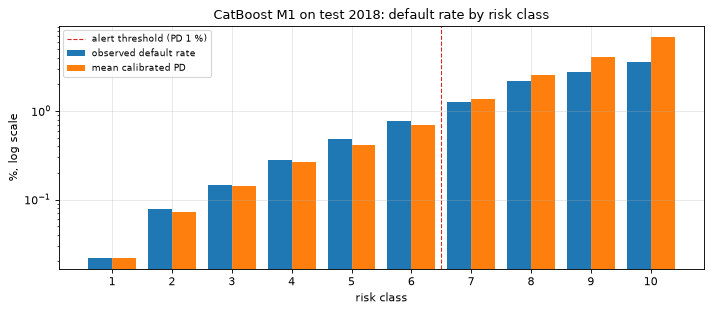

pd_range     rows  share_rows  defaults  share_defaults  default_rate  mean_pd  mean_relative_risk
model        grade                                                                                                          
CatBoost M1  1            < 0.05 %  1587234      0.4223       347          0.0444        0.0002   0.0002              0.1063
             2      0.05 % – 0.1 %   600217      0.1597       467          0.0597        0.0008   0.0007              0.3480
             3       0.1 % – 0.2 %   586434      0.1560       858          0.1097        0.0015   0.0014              0.6948
             4      0.2 % – 0.35 %   399293      0.1062      1115          0.1425        0.0028   0.0026              1.2795
             5      0.35 % – 0.5 %   196970      0.0524       952          0.1217        0.0048   0.0042              2.0158
             6         0.5 % – 1 %   249264      0.0663      1923          0.2458        0.0077   0.0069              3.3491
             7           1 % – 2 %   104178      0.0277      1313          0.1678        0.0126   0.0135              6.5271
             8         2 % – 3.5 %    25754      0.0069       556          0.0711        0.0216   0.0254             12.2508
             9         3.5 % – 5 %     6064      0.0016       169          0.0216        0.0279   0.0410             19.7703
             10              ≥ 5 %     3478      0.0009       124          0.0158        0.0357   0.0691             33.2839
Scorecard B0 1            < 0.05 %  1559523      0.4149       374          0.0478        0.0002   0.0002              0.1021
             2      0.05 % – 0.1 %   608897      0.1620       495          0.0633        0.0008   0.0007              0.3745
             3       0.1 % – 0.2 %   584562      0.1555       964          0.1232        0.0016   0.0014              0.7410
             4      0.2 % – 0.35 %   402512      0.1071      1167          0.1492        0.0029   0.0027              1.3732
             5      0.35 % – 0.5 %   206099      0.0548       937          0.1198        0.0045   0.0042              2.1621
             6         0.5 % – 1 %   271711      0.0723      2117          0.2706        0.0078   0.0070              3.5956
             7           1 % – 2 %   109860      0.0292      1468          0.1876        0.0134   0.0134              6.9122
             8         2 % – 3.5 %    14839      0.0039       280          0.0358        0.0189   0.0242             12.4899
             9         3.5 % – 5 %      822      0.0002        21          0.0027        0.0255   0.0392             20.2259
             10              ≥ 5 %       61      0.0000         1          0.0001        0.0164   0.0565             29.2315

In [2]:
rows = []
for key, name in MODELS.items():
    p = t[f"pd_{key}"].to_numpy()
    sc = rs.present(p, groups=m)
    g = pd.DataFrame({"grade": sc["grade"], "y1": y, "pd": p, "rr": sc["relative_risk"]})
    agg = g.groupby("grade").agg(rows=("y1", "size"), defaults=("y1", "sum"), default_rate=("y1", "mean"),
                                 mean_pd=("pd", "mean"), mean_relative_risk=("rr", "mean"))
    agg = agg.reindex(range(1, 11), fill_value=0)
    agg.insert(0, "pd_range", rs.grade_labels())
    agg["share_rows"] = agg["rows"] / len(g)
    agg["share_defaults"] = agg["defaults"] / y.sum()
    rows.append(agg.assign(model=name).reset_index())
grades = pd.concat(rows, ignore_index=True)
grades.to_csv(OUT / "risk_scale_grades.csv", index=False)

m1 = grades[grades["model"] == "CatBoost M1"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(m1["grade"] - 0.2, 100 * m1["default_rate"], width=0.4, label="observed default rate")
ax.bar(m1["grade"] + 0.2, 100 * m1["mean_pd"], width=0.4, label="mean calibrated PD")
ax.axvline(rs.ALERT_GRADE - 0.5, color="C3", ls="--", lw=1, label="alert threshold (PD 1 %)")
ax.set_yscale("log"); ax.set_xticks(range(1, 11)); ax.set_xlabel("risk class"); ax.set_ylabel("%, log scale")
ax.set_title("CatBoost M1 on test 2018: default rate by risk class"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
grades.set_index(["model", "grade"])[["pd_range", "rows", "share_rows", "defaults", "share_defaults", "default_rate", "mean_pd", "mean_relative_risk"]]

**EN. How to read.** For CatBoost M1 the observed default rate rises in every class without a single reversal: 0.02 % in class 1, 0.08 %, 0.15 %, 0.28 %, 0.48 %, 0.77 %, then 1.26 % in class 7 and 3.57 % in class 10, so the classes are meaningful risk levels. Class 1 holds 42 % of the loans and only 4.4 % of the defaults; classes 7–10 are exactly the alert list: 3.7 % of the loans and 27.6 % of the defaults. Inside the classes the calibration is close in the middle and too high at the top: mean PD 1.35 % vs 1.26 % observed in class 7, but 6.9 % vs 3.6 % in class 10 — the calibration slope of 0.93 (chapter 4: the highest PDs are a little too high). The scorecard B0 almost never reaches classes 9–10 (883 rows against 9,542 for M1): its PDs are compressed.

**RU. Как читать.** У CatBoost M1 фактическая доля дефолтов растёт в каждом классе без единого сбоя: 0,02 % в классе 1, 0,08 %, 0,15 %, 0,28 %, 0,48 %, 0,77 %, затем 1,26 % в классе 7 и 3,57 % в классе 10, то есть классы — осмысленные уровни риска. В классе 1 — 42 % кредитов и лишь 4,4 % дефолтов; классы 7–10 — это ровно список тревог: 3,7 % кредитов и 27,6 % дефолтов. Внутри классов калибровка близка в середине и завышена наверху: средняя PD 1,35 % при фактических 1,26 % в классе 7, но 6,9 % против 3,6 % в классе 10 — это наклон калибровки 0,93 (глава 4: самые высокие PD немного завышены). Скоринговая карта B0 почти не доходит до классов 9–10 (883 строки против 9 542 у M1): её прогнозы сжаты.

### 2. One PD, four ways to show it / Одна PD — четыре способа показать

**EN.** What a PD means on each scale: for typical PD values of CatBoost M1 on test — the relative risk (to the mean PD of the test portfolio), the percentile (share of test rows with a lower PD), the risk class and the points.

**RU.** Что означает PD на каждой шкале: для типичных значений PD модели CatBoost M1 на test — относительный риск (к средней PD портфеля test), процентиль (доля строк test с меньшей PD), класс риска и баллы.

In [3]:
p = np.sort(t["pd_m1_y1"].to_numpy())
mean_pd = p.mean()
ex = np.array([0.0005, 0.001, 0.002, 0.005, 0.01, 0.0155, 0.02, 0.05, 0.10])
examples = pd.DataFrame({"pd": ex, "relative_risk": ex / mean_pd, "percentile": np.searchsorted(p, ex, side="left") / len(p),
                         "grade": rs.grade(ex), "points": rs.score_points(ex)})
examples.to_csv(OUT / "risk_scale_examples.csv", index=False)
print(f"mean PD of M1 on test: {mean_pd:.4%}; alert list (PD >= 1 %) = top {np.mean(p >= 0.01):.1%} of rows")
examples

mean PD of M1 on test: 0.2071%; alert list (PD >= 1 %) = top 3.7% of rows


,pd,relative_risk,percentile,grade,points
0,0.0005,0.2414,0.4223,2,706.4241
1,0.0010,0.4827,0.5819,3,686.4097
2,0.0020,0.9655,0.7380,4,666.3808
3,0.0050,2.4137,0.8966,6,639.8554
4,0.0100,4.8275,0.9629,7,619.7100
5,0.0155,7.4826,0.9838,7,606.9039
6,0.0200,9.6549,0.9906,8,599.4171
7,0.0500,24.1373,0.9991,10,572.0814
8,0.1000,48.2746,0.9999,10,550.5214


**EN. How to read.** The mean PD of M1 on test is 0.21 %. A PD of 0.2 % is an average loan: relative risk 1.0, percentile 0.74 (the PD distribution is skewed: most loans are below the mean), class 4. The alert threshold PD = 1 % is a risk 4.8 times the average and percentile 0.963 — the top 3.7 % of the portfolio, class 7. The average alerted loan (PD 1.55 %) has a risk 7.5 times the average and is riskier than 98 % of the portfolio. A PD of 5 % is 24 times the average, percentile 0.999, class 10. On the points scale (higher = safer, 20 points halve the odds) these are 666, 620, 607 and 572 points.

**RU. Как читать.** Средняя PD модели M1 на test — 0,21 %. PD 0,2 % — обычный кредит: относительный риск 1,0, процентиль 0,74 (распределение PD скошено: у большинства кредитов PD ниже средней), класс 4. Порог тревоги PD = 1 % — риск в 4,8 раза выше среднего и процентиль 0,963, то есть верхние 3,7 % портфеля, класс 7. Средний кредит из списка тревог (PD 1,55 %) — риск в 7,5 раза выше среднего, рискованнее 98 % портфеля. PD 5 % — в 24 раза выше среднего, процентиль 0,999, класс 10. В баллах (больше — надёжнее, каждые 20 баллов вдвое уменьшают шансы дефолта) это 666, 620, 607 и 572 балла.

**EN. Summary.** From now on the risk of a loan is shown as four numbers: the calibrated PD (for expected loss and provisions), the relative risk, the percentile in the portfolio of the same date and the risk class 1–10; for example, "PD 1.55 % · 7.5 times the average · riskier than 98 % of the portfolio · class 7". The scales change only the presentation: the ranking, AUC, recall and the alert list are the same. On test the classes are monotone in the observed default rate, and classes 7–10 coincide with the alert list.

**RU. Итог.** Отныне риск кредита показывается четырьмя числами: откалиброванная PD (для ожидаемого убытка и резервов), относительный риск, процентиль в портфеле на ту же дату и класс риска 1–10; например, «PD 1,55 % · в 7,5 раза выше среднего · рискованнее 98 % портфеля · класс 7». Шкалы меняют только подачу: ранжирование, AUC, полнота и список тревог те же. На test классы монотонны по фактической доле дефолтов, а классы 7–10 совпадают со списком тревог.